# PartB - Fig. XX (a, b; portrait): glacier area versus mass response of the individual glacier models

For every glacier model and RGI region (Global on top, then the regions sorted by their 2020 glacier mass as in the other portrait figures and in GMIP3-comm Fig. 2), for the temperature bin 2.0°C to 4.0°C. One row per glacier model: **dot = median** over the climate scenarios, **line = likely range** (17th to 83rd percentile over the climate scenarios). Made for a width of 12 cm (same layout as `PartB_Cl_Fig1_portrait_model_differences.ipynb`).
- `a`: relative remaining area minus relative remaining mass at steady state (both relative to the **simulation start**, i.e. the RGI date, because there is no 2020 regional area, see `WIP_UNSAFE_PartB_0c_...area...ipynb`)
- `b`: area minus mass response timescale (80% of the total change, **non-shifted**, i.e. counted from the simulation start), from `PartB_0_area_vs_volume_response_time.ipynb`

Mass and volume are used synonymously here (constant ice density), so relative mass = relative volume.

This is NOT a difference to the multi-model median: every model is compared to itself (its area vs its mass response).

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import os
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
import matplotlib.patheffects as pe      # thin dark outline around the likely-range lines

In [2]:
plt.rcParams["pdf.use14corefonts"] = False  # don't convert text to path
plt.rcParams['pdf.fonttype'] = 42  # keep the text editable in the pdf

## Settings

In [3]:
# non-shifted, scaled and extended regional time series (volume and area), as in PartB_0
DATE = 'Feb12_2024'
fill_option = 'repeat_last_101yrs'
path_merged_runs_scaled_extend = f'../data/GMIP3_reg_glacier_model_data/glacierMIP3_{DATE}_models_all_rgi_regions_sum_scaled_extended_{fill_option}.nc'
fn_temp = '../data/climate_input_data/temp_ch_ipcc_ar6_isimip3b.csv'
# non-shifted area and volume response timescales (written by PartB_0)
fn_resp_time = 'PartB_data/resp_time_non_shifted_for_deltaT_rgi_reg_roll_volume_area_21yravg.csv'

temp_bin = [2.0, 4.0]            # global warming bin in °C
likely_range = [17, 83]          # percentiles over the climate scenarios
ss_years = [4900, 5000]          # steady state: mean over the last 101 simulation years (as in GMIP3-comm SM and PartB_0)
resp_time_perc = -80             # response timescale: 80% of the total change (-50 for the supplement)
max_missing = 0.25               # (b): region not shown if more than 25% of the experiments of one model have no estimate (as in PartB_2)

fig_width_cm, fig_height_cm = 8.3, 17    # one-column figure (include with width=8.3cm), max. ~17 cm so that figure + caption fit into one column
fs = 6  

x_lims = {'a': None, 'b': (-280, 150)}   # None: computed from the data (% points for a, years for b)
x_ticks = {'a': None, 'b': np.arange(-200, 101, 100)}

fig_dir = 'figures_partB/area_vs_mass/'
os.makedirs(fig_dir, exist_ok=True)

## Names, colours and order of the regions and glacier models

In [4]:
# region names without RGI numbers, with a line break where a name is long
reg_names_lines = {'All': 'Global', '01': 'Alaska', '02': 'W Canada & US', '03': 'Arctic Canada N', '04': 'Arctic Canada S',
                   '05': 'Greenland\nPeriphery', '06': 'Iceland', '07': 'Svalbard &\nJan Mayen', '08': 'Scandinavia',
                   '09': 'Russian Arctic', '10': 'North Asia', '11': 'Central Europe', '12': 'Caucasus &\nMiddle East',
                   '13': 'Central Asia', '14': 'South Asia W', '15': 'South Asia E', '16': 'Low Latitudes',
                   '17': 'Southern Andes', '18': 'New Zealand', '19': 'Subantarctic &\nAntarctic Islands'}

# Global on top, then sorted by the 2020 glacier mass (descending) as in Fig. 2 of GMIP3-comm (same as the other portrait figures)
reg_order = ['All', '19', '03', '01', '05', '09', '04', '07', '17', '06', '13', '14', '02', '15', '08', '10', '11', '16', '18', '12']

global_models = ['PyGEM-OGGM', 'GloGEMflow', 'OGGM', 'GLIMB']
regional_models = ['GloGEMflow3D', 'Kraaijenbrink', 'GO', 'CISM2']
model_names_data = {'PyGEM-OGGM_v13': 'PyGEM-OGGM', 'OGGM_v16': 'OGGM'}   # names in the data files, all others are the same
glac_models_data = ['PyGEM-OGGM_v13', 'GloGEMflow', 'OGGM_v16', 'GLIMB', 'GloGEMflow3D', 'Kraaijenbrink', 'GO', 'CISM2']  # without OGGM-VAS
dict_model_col = {'PyGEM-OGGM': '#5fb0e1', 'GloGEMflow': '#d18c14', 'OGGM': '#ca79bc', 'GLIMB': '#fab1e5',
                  'GloGEMflow3D': '#0f9373', 'Kraaijenbrink': '#c46011', 'GO': '#e5d73d', 'CISM2': '#562e10'}

## 1. Prepare the data
### (a) Steady state: relative remaining area minus relative remaining mass

In [5]:
ds = xr.open_dataset(path_merged_runs_scaled_extend)[['volume_m3', 'area_m2']].sel(model_author=glac_models_data)
assert int(ds.simulation_year.max()) == ss_years[1]

ds_0 = ds.sel(simulation_year=0).drop_vars('simulation_year')     # simulation start (RGI date)
ds_end = ds.sel(simulation_year=slice(*ss_years))
assert len(ds_end.simulation_year) == 101

# regions: relative remaining area and mass at steady state (% of the simulation start)
rel = 100 * ds_end.mean(dim='simulation_year') / ds_0
# Global: sum over the 19 regions (only the four global models have all 19 regions)
rel_glob = 100 * ds_end.sum(dim='rgi_reg', min_count=19).mean(dim='simulation_year') / ds_0.sum(dim='rgi_reg', min_count=19)
rel = xr.concat([rel_glob.expand_dims(rgi_reg=['All']), rel], dim='rgi_reg')

pd_a = rel.to_dataframe().reset_index().dropna(subset=['volume_m3', 'area_m2'])
pd_a['a'] = pd_a.area_m2 - pd_a.volume_m3       # > 0: relatively more area than mass remains
pd_a['model'] = pd_a.model_author.replace(model_names_data)
pd_a['reg'] = pd_a.rgi_reg

# global warming of every climate scenario
pd_temp = pd.read_csv(fn_temp, index_col=0)[['gcm', 'period_scenario', 'temp_ch_ipcc']]
assert not pd_temp.duplicated(['gcm', 'period_scenario']).any()
pd_a = pd_a.merge(pd_temp, on=['gcm', 'period_scenario'], how='left')
assert pd_a.temp_ch_ipcc.notna().all()

pd_a_bin = pd_a.loc[(pd_a.temp_ch_ipcc >= temp_bin[0]) & (pd_a.temp_ch_ipcc <= temp_bin[1])]
n_scen = len(pd_a_bin.groupby(['gcm', 'period_scenario']))
if temp_bin == [2.0, 4.0]:
    np.testing.assert_allclose(n_scen, 31)
# all models have all climate scenarios of the bin in every region where they exist
assert (pd_a_bin.groupby(['reg', 'model']).size() == n_scen).all()

### (b) Area minus mass response timescale
Recomputed from the raw response timescales of the non-shifted file (without OGGM-VAS). The 25% rule for the temperature bins is the same as in PartB_2, but applied to the experiments where both, the area and the mass response timescale, exist. It blanks Arctic Canada N and Subantarctic & Antarctic Islands (GloGEMflow) for 2.0°C to 4.0°C.

In [6]:
pd_rt = pd.read_csv(fn_resp_time, index_col=0)
assert not pd_rt.duplicated(['rgi_reg', 'model_author', 'gcm_period_scenario', 'metric']).any()
pd_rt = pd_rt.loc[pd_rt.model_author.isin(glac_models_data)].copy()    # without OGGM-VAS
pd_rt['model'] = pd_rt.model_author.replace(model_names_data)
pd_rt['reg'] = pd_rt.rgi_reg.str.replace('RGI', '')                     # 'All' stays 'All'
models_per_reg = pd_rt.groupby('reg').model.unique()                    # models that exist in a region (any temperature bin)

pd_rt_bin = pd_rt.loc[(pd_rt.temp_ch_ipcc >= temp_bin[0]) & (pd_rt.temp_ch_ipcc <= temp_bin[1])]
np.testing.assert_allclose(pd_rt_bin.gcm_period_scenario.nunique(), n_scen)
col = f'resp_time_{resp_time_perc}%'
pd_b = pd_rt_bin.pivot_table(index=['reg', 'model', 'gcm_period_scenario'], columns='metric', values=col).dropna().reset_index()
pd_b['b'] = pd_b.area_m2 - pd_b.volume_m3      # > 0: area responds slower than mass (years)

# 25% rule: number of experiments with both estimates per region and model (0 if a model has no estimate at all)
idx_all = pd.MultiIndex.from_tuples([(r, m) for r in models_per_reg.index for m in models_per_reg[r]], names=['reg', 'model'])
n_valid = pd_b.groupby(['reg', 'model']).size().reindex(idx_all, fill_value=0)
reg_na_b = sorted(n_valid.loc[n_valid < (1 - max_missing) * n_scen].index.get_level_values('reg').unique())
print('(b) regions not shown:', reg_na_b)
print('(b) models with less than', n_scen, 'experiments with both estimates:', n_valid.loc[n_valid < n_scen].to_dict())

(b) regions not shown: ['03', '19']
(b) models with less than 31 experiments with both estimates: {('03', 'GloGEMflow'): 21, ('03', 'OGGM'): 30, ('14', 'GloGEMflow'): 29, ('14', 'GloGEMflow3D'): 30, ('14', 'Kraaijenbrink'): 29, ('18', 'GloGEMflow'): 29, ('19', 'GloGEMflow'): 10}


### Median and likely range over the climate scenarios

In [7]:
def median_likely_range(pd_x, col):
    g = pd_x.groupby(['reg', 'model'])[col]
    return pd.DataFrame({'med': g.median(), 'lo': g.quantile(likely_range[0] / 100), 'hi': g.quantile(likely_range[1] / 100),
                         'n': g.count()})

pd_sums = {'a': median_likely_range(pd_a_bin, 'a'), 'b': median_likely_range(pd_b, 'b')}
pd_sums['b'].loc[pd_sums['b'].index.get_level_values('reg').isin(reg_na_b), ['med', 'lo', 'hi']] = np.nan
for p in ['a', 'b']:
    print(p, pd_sums[p].shape, '| range of the likely ranges:', np.round(pd_sums[p].lo.min(), 1), 'to', np.round(pd_sums[p].hi.max(), 1))

a (96, 4) | range of the likely ranges: -21.2 to 21.1
b (96, 4) | range of the likely ranges: -272.7 to 132.3


In [8]:
# numbers for the text (rounded, as in the manuscript)
pd.set_option('display.max_rows', 200)
pd.concat({p: pd_sums[p][['med', 'lo', 'hi']].round(0) for p in ['a', 'b']}, axis=1).reindex(reg_order, level='reg')

a                  b              
                    med    lo    hi    med     lo     hi
reg model                                               
All GLIMB          -1.0  -2.0   1.0 -136.0 -154.0 -119.0
    GloGEMflow     -5.0  -8.0  -3.0   19.0    9.0   45.0
    OGGM            2.0  -0.0   4.0   30.0   24.0   46.0
    PyGEM-OGGM      7.0   5.0   8.0  -19.0  -36.0   -8.0
19  GLIMB           6.0   5.0   7.0    NaN    NaN    NaN
    GloGEMflow     -9.0 -16.0   0.0    NaN    NaN    NaN
    OGGM            0.0  -4.0   6.0    NaN    NaN    NaN
    PyGEM-OGGM      7.0   5.0   8.0    NaN    NaN    NaN
03  GLIMB          -0.0  -1.0   1.0    NaN    NaN    NaN
    GloGEMflow     -2.0 -19.0   4.0    NaN    NaN    NaN
    OGGM            4.0  -4.0   7.0    NaN    NaN    NaN
    PyGEM-OGGM     12.0   8.0  14.0    NaN    NaN    NaN
01  GLIMB         -10.0 -11.0  -9.0  -22.0  -26.0  -19.0
    GloGEMflow     10.0   8.0  12.0   13.0    8.0   17.0
    OGGM            3.0  -4.0   7.0   10.0    8.0   22.0
    PyGEM-OGGM     10.0   9.0  12.0    8.0    4.0   11.0
05  GLIMB          -4.0 -12.0   3.0 -158.0 -256.0  -74.0
    GloGEMflow      3.0   2.0   4.0   27.0  -22.0   42.0
    OGGM            2.0   1.0   5.0   16.0   10.0   24.0
    PyGEM-OGGM      6.0   4.0   9.0    2.0   -8.0   12.0
09  GLIMB           0.0   0.0   0.0   25.0   14.0   41.0
    GloGEMflow      2.0   0.0   4.0   32.0   25.0   41.0
    OGGM            0.0  -1.0   0.0   77.0   54.0  132.0
    PyGEM-OGGM      1.0   0.0   3.0   81.0   49.0  105.0
04  GLIMB           0.0   0.0   1.0  -43.0  -55.0  -28.0
    GloGEMflow      8.0   2.0  11.0   39.0   33.0   58.0
    OGGM            3.0   1.0   8.0   35.0   29.0   48.0
    PyGEM-OGGM      1.0   0.0   4.0   44.0   31.0   52.0
07  GLIMB           0.0  -0.0   0.0   29.0   17.0   43.0
    GloGEMflow    -13.0 -21.0   0.0 -162.0 -273.0  -27.0
    OGGM            0.0   0.0   3.0   47.0   27.0   76.0
    PyGEM-OGGM      2.0   0.0   4.0   44.0   23.0   59.0
17  GLIMB          -3.0  -5.0  -1.0  -16.0  -19.0  -13.0
    GloGEMflow     19.0  15.0  21.0    8.0    6.0    9.0
    OGGM            9.0   8.0  11.0    6.0    4.0    8.0
    PyGEM-OGGM     15.0  14.0  17.0   -5.0   -8.0    1.0
06  GLIMB           4.0   2.0   5.0    1.0  -30.0   26.0
    GO              3.0   1.0   4.0    1.0   -1.0    3.0
    GloGEMflow      4.0   2.0  10.0   52.0   38.0   74.0
    GloGEMflow3D    2.0   1.0   4.0   46.0   27.0   50.0
    OGGM            3.0   1.0   5.0   49.0   37.0   67.0
    PyGEM-OGGM      3.0   1.0   5.0   52.0   42.0   68.0
13  GLIMB          -5.0  -6.0  -4.0  -16.0  -20.0  -13.0
    GloGEMflow     14.0  11.0  15.0   27.0   21.0   31.0
    GloGEMflow3D   10.0   7.0  10.0   14.0   11.0   18.0
    Kraaijenbrink  -0.0  -0.0   0.0    0.0    0.0    0.0
    OGGM            6.0   5.0   7.0    8.0    7.0   12.0
    PyGEM-OGGM     10.0   7.0  11.0   -3.0   -6.0    0.0
14  GLIMB          -5.0  -7.0  -2.0  -17.0  -21.0  -11.0
    GloGEMflow     16.0  15.0  18.0   26.0   21.0   28.0
    GloGEMflow3D   13.0  11.0  14.0   11.0    5.0   14.0
    Kraaijenbrink   0.0  -0.0   0.0    0.0    0.0    0.0
    OGGM           12.0  11.0  14.0    2.0    0.0    3.0
    PyGEM-OGGM     17.0  14.0  19.0  -15.0  -19.0  -13.0
02  GLIMB           0.0  -0.0   1.0   -7.0   -9.0   -6.0
    GloGEMflow      1.0   0.0   1.0    5.0    4.0    7.0
    GloGEMflow3D    0.0   0.0   1.0    0.0   -1.0    1.0
    OGGM            2.0   1.0   4.0    4.0    3.0    6.0
    PyGEM-OGGM      2.0   1.0   6.0    5.0    3.0    7.0
15  GLIMB          -0.0  -1.0  -0.0   -5.0   -5.0   -3.0
    GloGEMflow      8.0   5.0  11.0   10.0    7.0   14.0
    GloGEMflow3D    5.0   3.0   7.0    9.0    7.0   12.0
    Kraaijenbrink   0.0  -0.0   0.0    0.0    0.0    0.0
    OGGM            8.0   7.0  10.0    7.0    5.0    8.0
    PyGEM-OGGM      8.0   5.0  11.0    8.0    6.0   12.0
08  GLIMB           0.0   0.0   0.0   -7.0  -11.0   -3.0
    GloGEMflow      1.0   0.0   3.0   15.0   12.0   19.0
    GloGEMflow3D    0.0   0.0   

## 2. The figure

In [9]:
# CL: PRINTED sizes (the figure is created at its final size, one-column figure, include with width=8.3cm)
lw_rng, lw_out, ms_o, ms_d = 0.8, 1.3, 2.4, 2.1    # CL: line widths / marker sizes (as in the other portrait figures)

# one row per glacier model, the four global models first and then the regional models, with a gap between the regions
gap = 0.5      # CL: 0.5 instead of 0.7 rows between the regions (height)
rows, reg_centres, reg_spans = [], [], []
y = 0
for i, reg in enumerate(reg_order):
    models_reg = [m for m in global_models + regional_models if any((reg, m) in pd_sums[p].index for p in ['a', 'b'])]
    reg_spans.append((y - 0.5 - gap / 2, y + len(models_reg) - 0.5 + gap / 2, i))
    for k, m in enumerate(models_reg):
        rows.append((reg, m, y + k))
    reg_centres.append((y + (len(models_reg) - 1) / 2, reg))
    y = y + len(models_reg) + gap
y_max = y - gap - 0.5

outline = [pe.Stroke(linewidth=lw_out, foreground='0.25'), pe.Normal()]
arrow = dict(arrowstyle='-|>', color='k', lw=0.6, shrinkA=0, shrinkB=0, mutation_scale=5)   # mutation_scale sets the size of the arrow head


def nice_lims(pd_sum, step=10):
    # symmetric enough limits around the likely ranges, rounded to step
    lo, hi = np.nanmin(pd_sum.lo), np.nanmax(pd_sum.hi)
    return step * np.floor(min(lo, 0) / step - 0.5), step * np.ceil(max(hi, 0) / step + 0.5)


def area_mass_portrait_subplot(ax, pd_sum, x_lim, x_tick, xlabel, title, direction_labels):
    # one panel: median (dot) and likely range (line) over the climate scenarios for every glacier model and region
    for y_lo, y_hi, i in reg_spans:    # light background for every second region
        if i % 2 == 1:
            ax.axhspan(y_lo, y_hi, color='0.955', lw=0, zorder=0)
    for reg, m, y_row in rows:
        if (reg, m) not in pd_sum.index or np.isnan(pd_sum.loc[(reg, m)].med):      # no estimate
            continue
        r = pd_sum.loc[(reg, m)]
        marker = 'o' if m in global_models else 'D'
        ax.plot([r.lo, r.hi], [y_row] * 2, color=dict_model_col[m], lw=lw_rng, solid_capstyle='butt', zorder=2,
                path_effects=outline)
        ax.plot([r.med], [y_row], marker, ms=ms_o if marker == 'o' else ms_d,
                mfc=dict_model_col[m], mec='0.15', mew=0.35, zorder=3)
    for y_c, reg in reg_centres:      # regions without any estimate (e.g. Arctic Canada N and Subantarctic & Antarctic Islands in b)
        if not any(((reg, m) in pd_sum.index) and (not np.isnan(pd_sum.loc[(reg, m)].med)) for m in global_models + regional_models):
            ax.text(0.5, y_c, 'n/a', transform=ax.get_yaxis_transform(), ha='center', va='center', fontsize=fs, style='italic')
    ax.set_ylim(y_max, -0.5)
    ax.set_xlim(*x_lim)
    if x_tick is not None:
        ax.set_xticks(x_tick)
    ax.axvline(0, color='0.15', lw=0.9, zorder=1)
    ax.set_yticks([])
    ax.tick_params(axis='x', labelsize=fs, length=2, pad=1.5)
    ax.grid(axis='x', color='0.85', lw=0.4, zorder=0)
    for sp in ['top', 'right', 'left']:
        ax.spines[sp].set_visible(False)
    ax.set_xlabel(xlabel, fontsize=fs, labelpad=2, linespacing=1.0)      # CL: fs instead of fs + 0.5 (space)
    ax.set_title(title, fontsize=fs + 0.5, fontweight='bold', pad=13)     # CL: pad 13 instead of 17 (printed pt)
    # what the sign means: arrows left and right of zero, between the title and the panel
    trans = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
    dx = 0.02 * (x_lim[1] - x_lim[0])
    ax.annotate('', xy=(x_lim[0] + dx, 1.008), xytext=(-dx, 1.008), xycoords=trans, textcoords=trans, arrowprops=arrow)
    ax.annotate('', xy=(x_lim[1] - dx, 1.008), xytext=(dx, 1.008), xycoords=trans, textcoords=trans, arrowprops=arrow)
    ax.text(-dx, 1.014, direction_labels[0], transform=trans, ha='right', va='bottom', fontsize=fs)
    ax.text(dx, 1.014, direction_labels[1], transform=trans, ha='left', va='bottom', fontsize=fs)

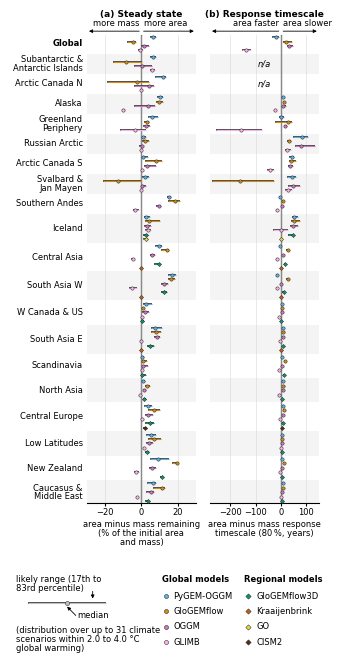

In [10]:
x_lims_plot = {p: (x_lims[p] if x_lims[p] is not None else nice_lims(pd_sums[p])) for p in ['a', 'b']}
# CL: ticks every 20 within the limits where none are given (the automatic ticks can be too dense for 2.8 cm wide panels)
x_ticks_plot = {p: (x_ticks[p] if x_ticks[p] is not None else
                    np.arange(20 * np.ceil(x_lims_plot[p][0] / 20), x_lims_plot[p][1] + 1e-6, 20)) for p in ['a', 'b']}
titles = {'a': '(a) Steady state',
          'b': '(b) Response timescale'}
# CL: wrapped for the 2.8 cm wide panels, space between number and unit (Copernicus figure guidelines)
xlabels = {'a': 'area minus mass remaining\n(% of the initial area\nand mass)',
           'b': f'area minus mass response\ntimescale ({abs(resp_time_perc)}\u202f%, years)'}
direction_labels = {'a': ['more mass', 'more area'],
                    'b': ['area faster', 'area slower']}

fig = plt.figure(figsize=(fig_width_cm / 2.54, fig_height_cm / 2.54))
# CL: panel positions in cm: column of the region names, gap between the panels, right margin
lab_w_cm, gap_cm, right_cm = 1.95, 0.35, 0.45
panel_w_cm = (fig_width_cm - lab_w_cm - gap_cm - right_cm) / 2
boxes = [(lab_w_cm / fig_width_cm, panel_w_cm / fig_width_cm),
         ((lab_w_cm + panel_w_cm + gap_cm) / fig_width_cm, panel_w_cm / fig_width_cm)]      # (left, width) of the panels
axes = []
for i_p, p in enumerate(['a', 'b']):
    ax = fig.add_axes([boxes[i_p][0], 0.225, boxes[i_p][1], 0.70])
    axes.append(ax)
    area_mass_portrait_subplot(ax, pd_sums[p], x_lims_plot[p], x_ticks_plot[p], xlabels[p], titles[p], direction_labels[p])

# names of the regions (without RGI numbers)
for y_c, reg in reg_centres:
    axes[0].text(-0.1 / panel_w_cm, y_c, reg_names_lines[reg], transform=axes[0].get_yaxis_transform(), ha='right', va='center',
                 fontsize=fs, fontweight='bold' if reg == 'All' else 'normal', linespacing=0.95)

# legend: dummy row with arrows, and the model names with their group as subtitle
# CL: rearranged for the 8.3 cm width, x in cm, all text at fs (as in the other portrait figures)
ax_leg = fig.add_axes([0.0, 0.0, 1.0, 0.12])
ax_leg.set_xlim(0, fig_width_cm)
ax_leg.set_ylim(0, 1)
ax_leg.axis('off')
x0_l, x1_l, y_l, x_med = 0.45, 2.45, 0.64, 1.45     # dummy likely range and median (cm)
ax_leg.plot([x0_l, x1_l], [y_l, y_l], color='0.75', lw=lw_rng, solid_capstyle='butt', path_effects=outline)
ax_leg.plot([x_med], [y_l], 'o', ms=3.0, mfc='0.75', mec='0.15', mew=0.35)
ax_leg.text(0.15, 0.99, f'likely range ({likely_range[0]}th to\n{likely_range[1]}rd percentile)', fontsize=fs, ha='left',
            va='top', linespacing=1.0)
ax_leg.annotate('', xy=(2.1, y_l + 0.05), xytext=(2.1, 0.78), arrowprops=arrow)
ax_leg.text(x_med + 0.25, 0.48, 'median', fontsize=fs, ha='left', va='center')
ax_leg.annotate('', xy=(x_med, y_l - 0.05), xytext=(x_med + 0.22, 0.48), arrowprops=arrow)
up_to = 'up to ' if (pd_sums['b'].n < n_scen).any() else ''
t0_str, t1_str = (f'{t:.1f}'.replace('-', '\u2212') for t in temp_bin)     # CL: real minus sign
ax_leg.text(0.15, 0.01, f'(distribution over {up_to}{n_scen} climate\nscenarios within {t0_str} to {t1_str} \u00b0C\nglobal warming)',
            fontsize=fs, ha='left', va='bottom', linespacing=1.0)

x_g, x_r, y_0, dy = 3.85, 5.95, 0.72, 0.19         # CL: start of the two model columns (cm)
ax_leg.text(x_g, 0.93, 'Global models', fontsize=fs, fontweight='bold', va='center')
ax_leg.text(x_r, 0.93, 'Regional models', fontsize=fs, fontweight='bold', va='center')
for k, m in enumerate(global_models):
    ax_leg.plot([x_g + 0.1], [y_0 - dy * k], 'o', ms=3.0, mfc=dict_model_col[m], mec='0.15', mew=0.35)
    ax_leg.text(x_g + 0.3, y_0 - dy * k, m, fontsize=fs, va='center')
for k, m in enumerate(regional_models):
    ax_leg.plot([x_r + 0.1], [y_0 - dy * k], 'D', ms=2.7, mfc=dict_model_col[m], mec='0.15', mew=0.35)
    ax_leg.text(x_r + 0.3, y_0 - dy * k, m, fontsize=fs, va='center')

fn_out = (f'{fig_dir}/manuscript_v0_area_minus_mass_steady_state_resp_time_{abs(resp_time_perc)}pct_portrait'
          f'_temp_bin_{temp_bin[0]}_{temp_bin[1]}')
plt.savefig(fn_out + '.png', dpi=300)
plt.savefig(fn_out + '.pdf')
plt.show()

## Suggested caption (LaTeX)

```latex
\caption{Glacier area versus mass response of the individual glacier models for global warming levels between 2.0$^\circ$C
and 4.0$^\circ$C (31 climate scenarios). (a) Relative remaining glacier area minus relative remaining glacier mass at steady
state, both in \% of the area and mass at the simulation start. Positive values indicate that relatively more area than mass
remains. (b) Area minus mass response timescale, i.e.\ the difference between the number of years from the simulation start
until 80\,\% of the total area change and of the total mass change has occurred. Positive values indicate that the area
responds slower than the mass. Global refers to the four global glacier models, regions are sorted by their 2020 glacier mass.
Dots show the median over the climate scenarios, lines the likely range (17th to 83rd percentile). n/a: more than 25\,\% of
the experiments of at least one glacier model do not allow an estimate of the area or mass response timescale.}
```